Importing Necessary Libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

Explore Data🔎

In [2]:
file_name = 'LeGiaBao_wrangled_validated.csv'
df = pd.read_csv(file_name) 

C:\Users\CHAU TINH TIEN\AppData\Local\Temp\ipykernel_4888\3603299897.py:2: DtypeWarning: Columns (0: Transaction ID) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_name)


# Bước 1 & 2 :Check Shape, Ý nghĩa từng cột, rà lại Missing/Invalid entries

In [14]:
print('=== BƯỚC 1 & 2: CHECK SHAPE, Ý NGHĨA CỘT & MISSING/INVALID ===\n')

# 1. Kiểm tra kích thước dữ liệu (shape)
print(f'- Kích thước DataFrame (Số dòng, Số cột): {df.shape}')
print(f'- Tổng số dòng: {df.shape[0]:,}')
print(f'- Tổng số cột: {df.shape[1]}\n')

# 2. Ý nghĩa các cột trong tập dữ liệu:
print('Ý nghĩa các cột chính:')
print('  + Transaction ID: Mã định danh duy nhất của mỗi giao dịch.')
print('  + Transaction Date: Ngày diễn ra giao dịch.')
print('  + Product Name: Tên sản phẩm/mặt hàng được bán.')
print('  + Quantity: Số lượng sản phẩm mua trong giao dịch đó.')
print('  + Price: Đơn giá của sản phẩm.')
print('  + Store Location: Vị trí cửa hàng hoặc hình thức phục vụ.')
print('  + Source: Nguồn thu thập dữ liệu hệ thống.')
print('  + Sales Amount: Tổng doanh thu của giao dịch (Quantity * Price).\n')

# 3. Kiểm tra giá trị thiếu (Missing Values)
missing_counts = df.isnull().sum()
print('Số lượng giá trị thiếu (Missing) theo từng cột:')
print(missing_counts)

=== BƯỚC 1 & 2: CHECK SHAPE, Ý NGHĨA CỘT & MISSING/INVALID ===

- Kích thước DataFrame (Số dòng, Số cột): (158656, 8)
- Tổng số dòng: 158,656
- Tổng số cột: 8

Ý nghĩa các cột chính:
  + Transaction ID: Mã định danh duy nhất của mỗi giao dịch.
  + Transaction Date: Ngày diễn ra giao dịch.
  + Product Name: Tên sản phẩm/mặt hàng được bán.
  + Quantity: Số lượng sản phẩm mua trong giao dịch đó.
  + Price: Đơn giá của sản phẩm.
  + Store Location: Vị trí cửa hàng hoặc hình thức phục vụ.
  + Source: Nguồn thu thập dữ liệu hệ thống.
  + Sales Amount: Tổng doanh thu của giao dịch (Quantity * Price).

Số lượng giá trị thiếu (Missing) theo từng cột:
Transaction ID      0
Transaction Date    0
Product Name        0
Quantity            0
Price               0
Store Location      0
Source              0
Sales Amount        0
dtype: int64


# Bước 3: phát hiện outlier bằng IQR, quyết định drop hay clip/winsorize

In [16]:
print('=== BƯỚC 3: PHÁT HIỆN OUTLIER BẰNG PHƯƠNG PHÁP IQR ===\n')

numeric_cols = ['Quantity', 'Price', 'Sales Amount']

for col in numeric_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  # Lọc các dòng ngoại lệ
  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
  print(f'Cột [{col}]:')
  print(f'  * Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}')
  print(f'  * Ngưỡng dưới: {lower_bound:.2f} | Ngưỡng trên: {upper_bound:.2f}')
  print(
      f'  * Số lượng outlier phát hiện: {len(outliers):,} ({len(outliers)/len(df)*100:.2f}%)'
  )
  print('-' * 50)

print('\nQUYẾT ĐỊNH XỬ LÝ:')
print(
    '-> Trong bài toán bán hàng thực tế, các giá trị outlier ở mức cao đại diện'
    ' cho các đơn hàng mua sỉ hoặc mua số lượng lớn hợp lệ của khách hàng.'
)
print(
    '-> Do đó, ta GIỮ NGUYÊN dữ liệu (không drop) để phản ánh đúng thực tế kinh'
    ' doanh, hoặc có thể dùng phương pháp clip/winsorize nếu xây dựng mô hình'
    ' học máy nhạy cảm với ngoại lệ.'
)

=== BƯỚC 3: PHÁT HIỆN OUTLIER BẰNG PHƯƠNG PHÁP IQR ===

Cột [Quantity]:
  * Q1 = 1.0, Q3 = 2.0, IQR = 1.0
  * Ngưỡng dưới: -0.50 | Ngưỡng trên: 3.50
  * Số lượng outlier phát hiện: 3,724 (2.35%)
--------------------------------------------------
Cột [Price]:
  * Q1 = 2.5, Q3 = 3.75, IQR = 1.25
  * Ngưỡng dưới: 0.62 | Ngưỡng trên: 5.62
  * Số lượng outlier phát hiện: 4,212 (2.65%)
--------------------------------------------------
Cột [Sales Amount]:
  * Q1 = 3.0, Q3 = 6.0, IQR = 3.0
  * Ngưỡng dưới: -1.50 | Ngưỡng trên: 10.50
  * Số lượng outlier phát hiện: 6,469 (4.08%)
--------------------------------------------------

QUYẾT ĐỊNH XỬ LÝ:
-> Trong bài toán bán hàng thực tế, các giá trị outlier ở mức cao đại diện cho các đơn hàng mua sỉ hoặc mua số lượng lớn hợp lệ của khách hàng.
-> Do đó, ta GIỮ NGUYÊN dữ liệu (không drop) để phản ánh đúng thực tế kinh doanh, hoặc có thể dùng phương pháp clip/winsorize nếu xây dựng mô hình học máy nhạy cảm với ngoại lệ.


BƯỚC 4: DESCRIBE(), HISTOGRAM, COUNTPLOT (MATPLOTLIB)

=== BƯỚC 4: DESCRIBE() & TRỰC QUAN HÓA (MATPLOTLIB) ===

            Quantity          Price   Sales Amount
count  158656.000000  158656.000000  158656.000000
mean        1.533633       3.356391       4.941879
std         0.730713       2.597527       4.456045
min         1.000000       0.800000       0.800000
25%         1.000000       2.500000       3.000000
50%         1.000000       3.000000       4.000000
75%         2.000000       3.750000       6.000000
max         8.000000      45.000000     360.000000

Đã lưu file biểu đồ thành công: data_distribution_analysis.png (có thể đính kèm báo cáo).


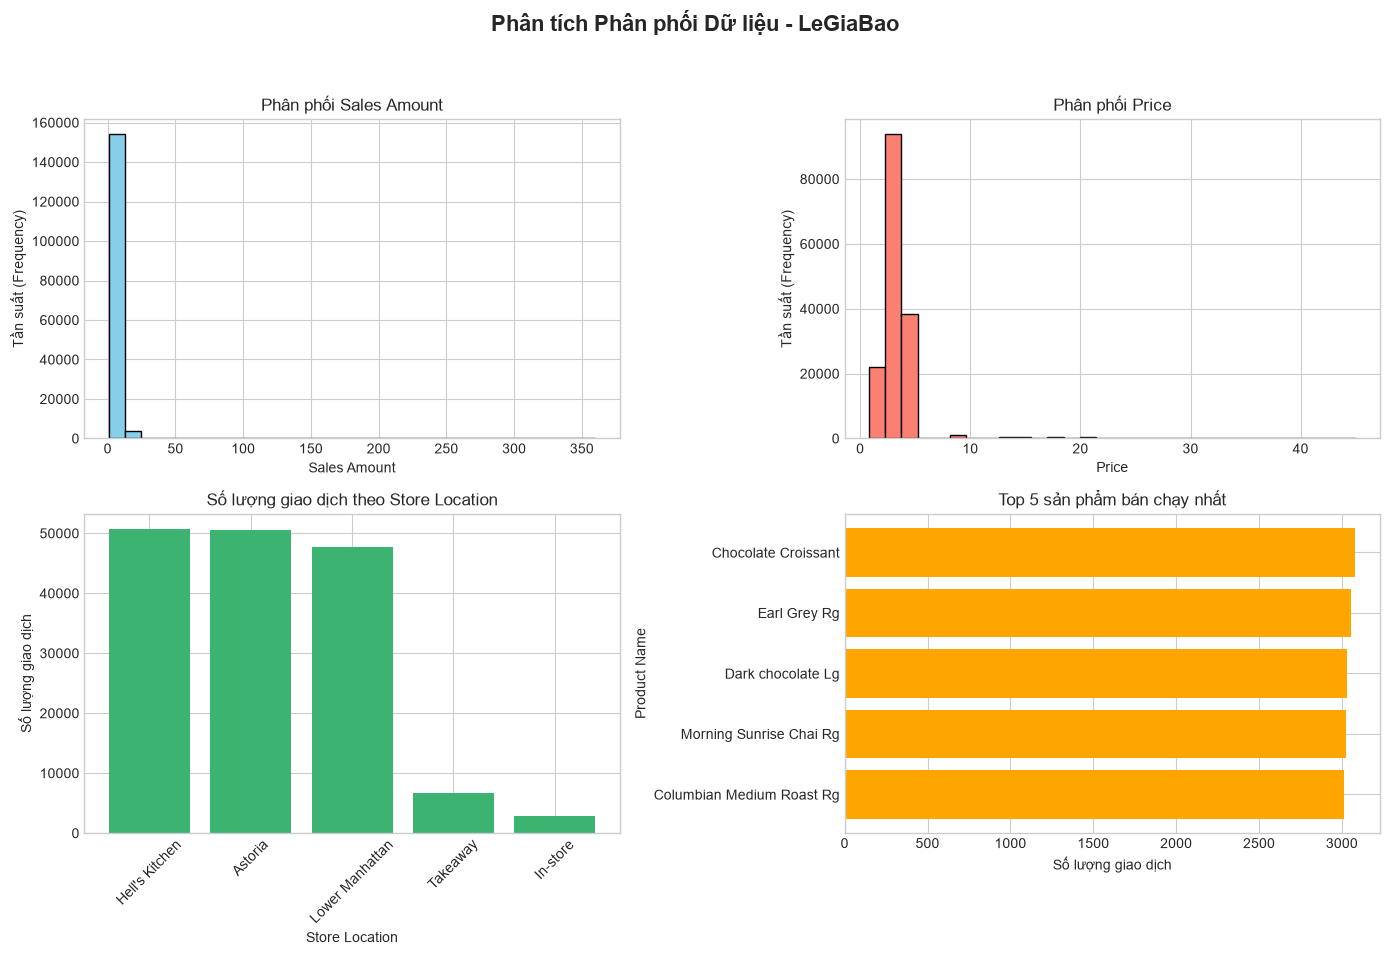

In [17]:
print('=== BƯỚC 4: DESCRIBE() & TRỰC QUAN HÓA (MATPLOTLIB) ===\n')

# 1. Thống kê mô tả
print(df[numeric_cols].describe())

# 2. Thiết lập vẽ biểu đồ (Matplotlib)
plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
fig.suptitle(
    'Phân tích Phân phối Dữ liệu - LeGiaBao', fontsize=16, fontweight='bold'
)

# Biểu đồ 1: Histogram Sales Amount
axes[0, 0].hist(df['Sales Amount'], bins=30, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Phân phối Sales Amount')
axes[0, 0].set_xlabel('Sales Amount')
axes[0, 0].set_ylabel('Tần suất (Frequency)')

# Biểu đồ 2: Histogram Price
axes[0, 1].hist(df['Price'], bins=30, color='salmon', edgecolor='black')
axes[0, 1].set_title('Phân phối Price')
axes[0, 1].set_xlabel('Price')
axes[0, 1].set_ylabel('Tần suất (Frequency)')

# Biểu đồ 3: Countplot / Bar chart Store Location
store_counts = df['Store Location'].value_counts()
axes[1, 0].bar(
    store_counts.index.astype(str), store_counts.values, color='mediumseagreen'
)
axes[1, 0].set_title('Số lượng giao dịch theo Store Location')
axes[1, 0].set_xlabel('Store Location')
axes[1, 0].set_ylabel('Số lượng giao dịch')
axes[1, 0].tick_params(axis='x', rotation=45)

# Biểu đồ 4: Top 5 Product Name phổ biến nhất
top_products = df['Product Name'].value_counts().head(5)
axes[1, 1].barh(
    top_products.index[::-1].astype(str), top_products.values[::-1], color='orange'
)
axes[1, 1].set_title('Top 5 sản phẩm bán chạy nhất')
axes[1, 1].set_xlabel('Số lượng giao dịch')
axes[1, 1].set_ylabel('Product Name')

# Tối ưu layout và lưu ảnh
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('data_distribution_analysis.png', dpi=300, bbox_inches='tight')
print(
    '\nĐã lưu file biểu đồ thành công: data_distribution_analysis.png (có thể'
    ' đính kèm báo cáo).'
)

plt.show()

# Save Cleaned Dataset

In [20]:
OUTPUT_PATH = 'PhamVietTien_LoadMissingInvalidOutliersDistributions.csv'
df.to_csv(OUTPUT_PATH, index=False)
print(f'Saved cleaned dataset to: {OUTPUT_PATH}')

Saved cleaned dataset to: PhamVietTien_LoadMissingInvalidOutliersDistributions.csv
